# Гипотеза 5: Влияние сверхурочной работы на текучесть

## Данные
Таблица `V4_Employee_cleaned.csv`.

## Цель
Провести проверку гипотезы:

Нулевая гипотеза (H0): доля уволившихся среди сотрудников со сверхурочной работой (overtime = Yes) равна доле уволившихся среди сотрудников без сверхурочной работы (overtime = No).

Альтернативная гипотеза (H1): доля уволившихся среди сотрудников со сверхурочной работой (Yes) отличается от доли среди сотрудников без сверхурочной работы (No), причем сотрудники со сверхурочной работой уходят чаще.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, norm

# Загрузка данных

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
print(os.listdir('/content/drive/MyDrive'))

print(os.listdir('/content/drive/MyDrive/Проект команды 3'))

path = '/content/drive/MyDrive/Проект команды 3/'
df = pd.read_csv(path + "V4_Employee_cleaned.csv")

Mounted at /content/drive
['Проект команды 3', 'Личное']
['DimDate.txt', 'EducationLevel.csv', 'Employee.csv', 'PerformanceRating.csv', 'RatingLevel.csv', 'SatisfiedLevel.csv', 'V4_Employee_cleaned.csv', 'V4_Проект_команды_3_Предобработка_данных.ipynb', 'Архив', 'Проект_команды_3_Гипотеза_2.ipynb', 'Гипотеза 6.ipynb', 'Проект_команды_3_Проверка гипотезы 1.ipynb', 'Проект команды 3_Гипотеза 4.ipynb', 'Проект_команды_3_Гипотеза_5.ipynb']


## Параметры (фиксируются ДО анализа)

In [7]:
# =================== ПАРАМЕТРЫ (фиксируются ДО анализа) ===================
PRACTICAL_SIGNIFICANCE_PP = 5.0   # порог практически значимого эффекта, п.п.
ALPHA = 0.05                      # уровень значимости
TARGET = "attrition_flag"         # целевой показатель (0 = остался, 1 = уволился)
PREDICTOR = "overtime"            # сверхурочная работа (Yes / No)
EMPLOYEE_KEY = "employeeid"       # единица наблюдения
# =====================================================================

## 0. Структура данных (единица наблюдения, гранулярность, ключи)

In [8]:
print("=" * 70)
print("0. СТРУКТУРА ДАННЫХ")
print("=" * 70)
print(f"Размер таблицы: {df.shape[0]} строк × {df.shape[1]} столбцов")
print(f"Единица наблюдения: {EMPLOYEE_KEY} (один сотрудник)")
print(f"Ключ уникален: {df[EMPLOYEE_KEY].is_unique}")
print(f"Дубликаты ключа: {df.duplicated(subset=[EMPLOYEE_KEY]).sum()}")
print("Гранулярность: одна строка = один сотрудник, последний доступный опрос")

print("\nТипы ключевых полей:")
for col in [EMPLOYEE_KEY, PREDICTOR, TARGET, "department", "jobrole", "salary_band", "age_group"]:
    if col in df.columns:
        print(f"  {col}: {df[col].dtype}")

0. СТРУКТУРА ДАННЫХ
Размер таблицы: 1470 строк × 46 столбцов
Единица наблюдения: employeeid (один сотрудник)
Ключ уникален: True
Дубликаты ключа: 0
Гранулярность: одна строка = один сотрудник, последний доступный опрос

Типы ключевых полей:
  employeeid: object
  overtime: object
  attrition_flag: int64
  department: object
  jobrole: object
  salary_band: object
  age_group: object


## 1. Пропуски, специальные значения и проверка предикатора

In [9]:
print("\n" + "=" * 70)
print("1. ПРОПУСКИ, СПЕЦИАЛЬНЫЕ ЗНАЧЕНИЯ И ПРОВЕРКА ПРЕДИКАТОРА")
print("=" * 70)
key_cols = [PREDICTOR, TARGET, "department", "jobrole", "salary_band", "age_group",
            "gender", "overtime", "businesstravel", "worklifebalance"]
for col in key_cols:
    if col in df.columns:
        nan_cnt = int(df[col].isna().sum())
        print(f"  {col}: пропусков = {nan_cnt} ({nan_cnt/len(df)*100:.1f}%)")

print(f"\nУникальные значения {PREDICTOR}: {sorted(df[PREDICTOR].dropna().unique())}")
print(f"Уникальные значения {TARGET}: {sorted(df[TARGET].dropna().unique())}")

bad_pred = df[~df[PREDICTOR].isin(["Yes", "No"]) & df[PREDICTOR].notna()]
bad_tgt = df[~df[TARGET].isin([0, 1]) & df[TARGET].notna()]
print(f"\n{PREDICTOR} вне значений Yes/No: {len(bad_pred)} строк")
print(f"{TARGET} не 0/1: {len(bad_tgt)} строк")

# Метки для читаемости
df['attrition_label'] = df[TARGET].map({0: 'остался', 1: 'уволился'})

print("\nРаспределение сверхурочной работы:")
print(df[PREDICTOR].value_counts())


1. ПРОПУСКИ, СПЕЦИАЛЬНЫЕ ЗНАЧЕНИЯ И ПРОВЕРКА ПРЕДИКАТОРА
  overtime: пропусков = 0 (0.0%)
  attrition_flag: пропусков = 0 (0.0%)
  department: пропусков = 0 (0.0%)
  jobrole: пропусков = 0 (0.0%)
  salary_band: пропусков = 0 (0.0%)
  age_group: пропусков = 0 (0.0%)
  gender: пропусков = 0 (0.0%)
  overtime: пропусков = 0 (0.0%)
  businesstravel: пропусков = 0 (0.0%)
  worklifebalance: пропусков = 381 (25.9%)

Уникальные значения overtime: ['No', 'Yes']
Уникальные значения attrition_flag: [np.int64(0), np.int64(1)]

overtime вне значений Yes/No: 0 строк
attrition_flag не 0/1: 0 строк

Распределение сверхурочной работы:
overtime
No     1054
Yes     416
Name: count, dtype: int64


## 2. Временное и объектное покрытие, ограничения датасета

In [10]:
print("\n" + "=" * 70)
print("2. ПОКРЫТИЕ И ОГРАНИЧЕНИЯ")
print("=" * 70)
if "reviewdate" in df.columns:
    df["reviewdate"] = pd.to_datetime(df["reviewdate"], errors="coerce")
    print(f"reviewdate: min = {df['reviewdate'].min()}, max = {df['reviewdate'].max()}, пропусков = {int(df['reviewdate'].isna().sum())}")
print(f"Отделов: {df['department'].nunique() if 'department' in df.columns else 'н/д'}")
print(f"Должностей: {df['jobrole'].nunique() if 'jobrole' in df.columns else 'н/д'}")
print("Ограничение: перекрестные данные (одна волна опроса). Причинность недоказуема.")


2. ПОКРЫТИЕ И ОГРАНИЧЕНИЯ
reviewdate: min = 2013-04-12 00:00:00, max = 2022-11-21 00:00:00, пропусков = 381
Отделов: 3
Должностей: 13
Ограничение: перекрестные данные (одна волна опроса). Причинность недоказуема.


##3. Разведочный анализ (EDA): визуализация текучести по сверхурочной работе

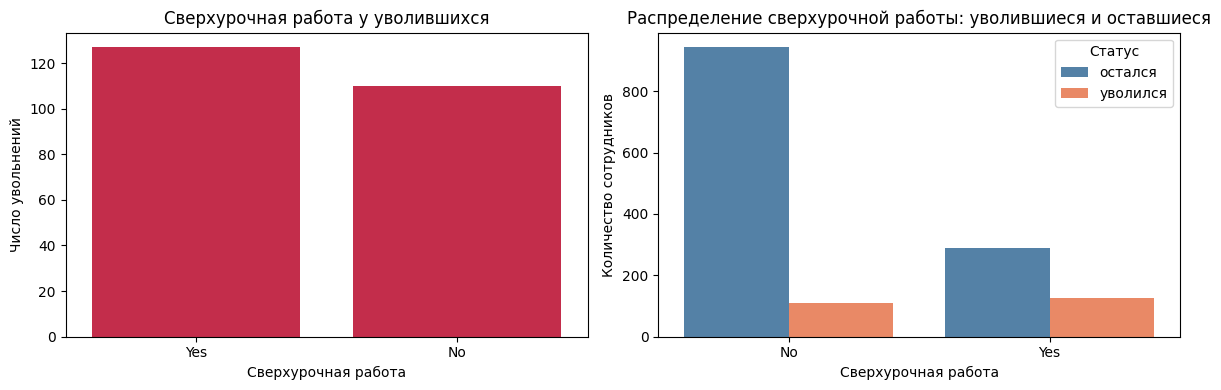

In [11]:
# Уволившиеся по группам сверхурочной работы
df_exited = df[df[TARGET] == 1]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
ot_counts_exited = df_exited[PREDICTOR].value_counts().reindex(['Yes', 'No'])
sns.barplot(x=ot_counts_exited.index, y=ot_counts_exited.values, color='crimson')
plt.title('Сверхурочная работа у уволившихся')
plt.xlabel('Сверхурочная работа')
plt.ylabel('Число увольнений')
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
sns.countplot(
    data=df,
    x=PREDICTOR,
    hue='attrition_label',
    hue_order=['остался', 'уволился'],
    palette={'остался': 'steelblue', 'уволился': 'coral'}
)
plt.title('Распределение сверхурочной работы: уволившиеся и оставшиеся')
plt.xlabel('Сверхурочная работа')
plt.ylabel('Количество сотрудников')
plt.legend(title='Статус')

plt.tight_layout()
plt.show()

/tmp/ipykernel_6102/2547945674.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(


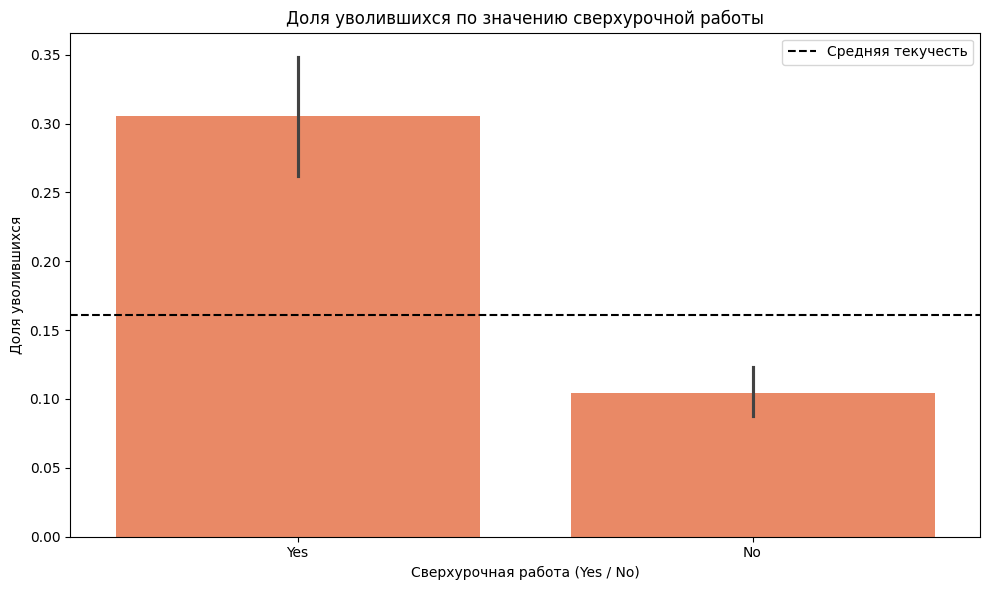

In [12]:
# Доля уволившихся по значению сверхурочной работы (Yes / No)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df,
    x=PREDICTOR,
    y=TARGET,
    order=['Yes', 'No'],
    ci=95,
    color='coral'
)
plt.axhline(df[TARGET].mean(), color='black', linestyle='--',
            label='Средняя текучесть')
plt.title('Доля уволившихся по значению сверхурочной работы')
plt.xlabel('Сверхурочная работа (Yes / No)')
plt.ylabel('Доля уволившихся')
plt.legend()
plt.tight_layout()
plt.show()

**Вывод**: визуально доля уволившихся при сверхурочной работе (Yes) и без нее (No) сравнима — отклонения лежат внутри доверительных интервалов.

##4. Кросс-таблица и хи-квадрат (глобальная проверка)

In [13]:
print("\n" + "=" * 70)
print("4. КРОСС-ТАБЛИЦА: СВЕРХУРОЧНАЯ РАБОТА × ТЕКУЧЕСТЬ")
print("=" * 70)

ct = pd.crosstab(df[PREDICTOR], df[TARGET])
ct["all"] = ct.sum(axis=1)
ct["attrition_rate_%"] = (ct[1] / ct["all"] * 100).round(2)
print(ct.to_string())

yes = df[df[PREDICTOR] == "Yes"][TARGET]
no  = df[df[PREDICTOR] == "No"][TARGET]

rate_yes  = yes.mean() * 100
rate_no   = no.mean() * 100
diff_pp   = rate_yes - rate_no

count_yes  = int(yes.sum())
count_no   = int(no.sum())
nobs_yes   = int(len(yes))
nobs_no    = int(len(no))

print(f"\nНаблюдение 1: текучесть при сверхурочной работе = {rate_yes:.1f}% (n={nobs_yes})")
print(f"Наблюдение 2: текучесть без сверхурочной работы = {rate_no:.1f}% (n={nobs_no})")
print(f"Наблюдение 3: разница (Yes − No) = {diff_pp:.1f} процентных пункта")

chi2, p, dof, expected = chi2_contingency(ct[[0, 1]].values)
n = ct.values.sum()
cramer_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1))) if min(ct.shape) > 1 else np.nan

print(f"\nХи-квадрат = {chi2:.2f}, df = {dof}, p-value = {p:.4f}")
print(f"Крамер V = {cramer_v:.3f}")


4. КРОСС-ТАБЛИЦА: СВЕРХУРОЧНАЯ РАБОТА × ТЕКУЧЕСТЬ
attrition_flag    0    1   all  attrition_rate_%
overtime                                        
No              944  110  1054             10.44
Yes             289  127   416             30.53

Наблюдение 1: текучесть при сверхурочной работе = 30.5% (n=416)
Наблюдение 2: текучесть без сверхурочной работы = 10.4% (n=1054)
Наблюдение 3: разница (Yes − No) = 20.1 процентных пункта

Хи-квадрат = 87.56, df = 1, p-value = 0.0000
Крамер V = 0.171


**Вывод**: χ² = 87.56, df = 1, p-value = 0.0000 < 0.05 - различие между группами статистически значимо. Разница в текучести 20.1 п.п. (30.5% vs 10.4%), что значительно превышает заранее заданный порог в 5 п.п. — эффект практически значим. Крамер V = 0.171 — связь умеренная (надежная ассоциация между сверхурочной работой и текучестью). Сотрудники со сверхурочной работой уходят примерно в три раза чаще (30.5% против 10.4%).

## 5. Статистическая значимость (z-тест)

In [14]:
print("\n" + "=" * 70)
print("5. СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ (Yes vs No)")
print("=" * 70)

try:
    from statsmodels.stats.proportion import proportions_ztest
    HAS_STATSMODELS = True
except ImportError:
    HAS_STATSMODELS = False

print(f"Сверхурочно (Yes):  текучесть {rate_yes:.1f}% (n={nobs_yes})")
print(f"Без сверхурочных (No): текучесть {rate_no:.1f}% (n={nobs_no})")
print(f"Разница (Yes − No): {diff_pp:.1f} п.п.")

if HAS_STATSMODELS:
    z_stat, p_z = proportions_ztest([count_yes, count_no], [nobs_yes, nobs_no])
else:
    from scipy.stats import norm
    pooled_p = (count_yes + count_no) / (nobs_yes + nobs_no)
    se = np.sqrt(pooled_p * (1 - pooled_p) * (1 / nobs_yes + 1 / nobs_no))
    p1 = count_yes / nobs_yes
    p2 = count_no / nobs_no
    z_stat = (p1 - p2) / se
    p_z = 2 * (1 - norm.cdf(abs(z_stat)))

print(f"\nZ-тест: z = {z_stat:.2f}, p-value = {p_z:.4f}")


5. СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ (Yes vs No)
Сверхурочно (Yes):  текучесть 30.5% (n=416)
Без сверхурочных (No): текучесть 10.4% (n=1054)
Разница (Yes − No): 20.1 п.п.

Z-тест: z = 9.44, p-value = 0.0000


**Вывод**: z = 9.44 — это гораздо выше критического значения (≈ 1.96 при α = 0.05), то есть наблюдаемая разница не может быть объяснена случайностью.
p-value = 0.0000 < 0.05 — статистически значимо. Нулевая гипотеза H0 (доли уволившихся равны) отвергается. Разница 20.1 п.п. значительно превышает заранее заданный порог практически значимости (5 п.п.).

## 6. Практически значимый эффект (порог задан ДО анализа)

In [15]:
print("\n" + "=" * 70)
print("6. ПРАКТИЧЕСКАЯ ЗНАЧИМОСТЬ")
print("=" * 70)
print(f"Порог практически значимого эффекта: {PRACTICAL_SIGNIFICANCE_PP} п.п.")
print(f"Полученный эффект: {diff_pp:.1f} п.п.")
print(f"Практически значим: {'ДА' if abs(diff_pp) >= PRACTICAL_SIGNIFICANCE_PP else 'НЕТ'}")


6. ПРАКТИЧЕСКАЯ ЗНАЧИМОСТЬ
Порог практически значимого эффекта: 5.0 п.п.
Полученный эффект: 20.1 п.п.
Практически значим: ДА


##7. Корреляция

In [16]:
print("=" * 70)
print("7. КОРРЕЛЯЦИЯ (точечная корреляция Пирсона: overtime × attrition_flag)")
print("=" * 70)

overtime_num = df[PREDICTOR].map({'Yes': 1, 'No': 0})
corr_pb = overtime_num.corr(df[TARGET])

print(f"Точечная корреляция Пирсона (overtime × attrition_flag): {corr_pb:.4f}")

7. КОРРЕЛЯЦИЯ (точечная корреляция Пирсона: overtime × attrition_flag)
Точечная корреляция Пирсона (overtime × attrition_flag): 0.2461


**Вывод**: r = 0.2461 — положительная, умеренная связь. Сотрудники со сверхурочной работой (overtime = 1) чаще уходят из компании (attrition_flag = 1). r² ≈ 0.06 — примерно 6% вариативности текучести объясняется сверхурочной работой. Остальные 94% зависят от других факторов (зарплата, роль, отдел и т.д.). Вместе с χ² (p = 0.0000) и z-тестом (p = 0.0000) это подтверждает: связь статистически значима и не случайна.

## 8. Бизнес-влияние (гипотетическая оценка)

In [17]:
print("=" * 70)
print("8. БИЗНЕС-ВЛИЯНИЕ (гипотетическая оценка)")
print("=" * 70)

if diff_pp > 0:
    n_yes = len(yes)
    excess_leavers = int(n_yes * (diff_pp / 100))
    print(f"Сотрудников со сверхурочной работой: {n_yes}")
    print(f"Избыточные увольнения при разнице {diff_pp:.1f} п.п.: {excess_leavers} человек")
    print(f"\nПри средней зарплате {df['salary'].mean():,.0f} руб. и стоимости замещения сотрудника ≈ 50% от годовой зарплаты:")
    avg_salary = df['salary'].mean()
    cost_per_leaver = avg_salary * 0.5
    total_cost = excess_leavers * cost_per_leaver
    print(f"  Потенциальная экономия при устранении разницы: {total_cost:,.0f} руб.")
else:
    print("Разница не положительная — избыточных увольнений в группе со сверхурочной работой не выявлено.")

8. БИЗНЕС-ВЛИЯНИЕ (гипотетическая оценка)
Сотрудников со сверхурочной работой: 416
Избыточные увольнения при разнице 20.1 п.п.: 83 человек

При средней зарплате 112,956 руб. и стоимости замещения сотрудника ≈ 50% от годовой зарплаты:
  Потенциальная экономия при устранении разницы: 4,687,695 руб.


**Вывод**: Если бы текучесть среди сотрудников со сверхурочной работой была такой же, как у сотрудников без сверхурочных, компания избежала бы примерно 83 избыточных увольнения. При средней зарплате ~112 956 руб. и стоимости замещения одного сотрудника ≈ 50% от годового оклада, потенциальная экономия составляет около 4,69 млн руб. Это означает, что сверхурочная работа обходится компании существенно дороже, чем экономия на оплате дополнительных часов.

## 9. Перепроверка по сегментам (отделы)

In [19]:
print("\n" + "=" * 70)
print("9. ПЕРЕПРОВЕРКА ПО СЕГМЕНТАМ (отделы)")
print("=" * 70)
strata_rows = []
for dept, sub in df.groupby("department"):
    s_yes = sub[sub[PREDICTOR] == "Yes"][TARGET]
    s_no  = sub[sub[PREDICTOR] == "No"][TARGET]
    if len(s_yes) > 0 and len(s_no) > 0:
        strata_rows.append({
            "department": dept,
            "n_yes": len(s_yes), "rate_yes_%": round(s_yes.mean() * 100, 1),
            "n_no": len(s_no), "rate_no_%": round(s_no.mean() * 100, 1),
            "diff_pp": round((s_yes.mean() - s_no.mean()) * 100, 1)
        })
strata_df = pd.DataFrame(strata_rows).sort_values("diff_pp", ascending=False)
print(strata_df.to_string(index=False))


9. ПЕРЕПРОВЕРКА ПО СЕГМЕНТАМ (отделы)
     department  n_yes  rate_yes_%  n_no  rate_no_%  diff_pp
          Sales    128        37.5   318       13.8     23.7
     Technology    271        27.3   690        8.6     18.8
Human Resources     17        29.4    46       15.2     14.2


**Вывод:** Эффект консистентен во всех отделах: в каждом из трех отделов текучесть среди сотрудников со сверхурочной работой выше, чем без неё.
Sales: 37.5% vs 13.8% → разница +23.7 п.п.
Technology: 27.3% vs 8.6% → разница +18.8 п.п.
Human Resources: 29.4% vs 15.2% → разница +14.2 п.п.
Все разницы значительно превышают заранее заданный порог практически значимости (5 п.п.) — даже минимальный эффект в HR (14.2 п.п.) почти в три раза выше порога.
Нет обратной зависимости ни в одном отделе — парадокса Симпсона не наблюдается, отдел не является смешивающим фактором, который объяснял бы общую связь.
Самый критичный отдел — Sales: высочайшая текучесть среди «сверхурочников» (37.5%) и наибольший разрыв (23.7 п.п.). Здесь ограничение сверхурочных даст наибольший эффект.

## 10. Наблюдение / Интерпретация / Влияние / Ограничение

In [20]:
print("\n" + "=" * 70)
print("10. НАБЛЮДЕНИЕ / ИНТЕРПРЕТАЦИЯ / ВЛИЯНИЕ / ОГРАНИЧЕНИЕ")
print("=" * 70)
print(f"1) Наблюдение: при Overtime = Yes текучесть {rate_yes:.1f}%, при Overtime = No — {rate_no:.1f}%. Разница {diff_pp:.1f} п.п.")
print(f"2) Интерпретация: возможная ассоциация между сверхурочной работой и уходом. НЕ причинность (перекрестные данные; возможна обратная причинность — сотрудники, решающие уйти, могут набирать больше сверхурочных перед увольнением).")
print(f"3) Влияние на гипотезу: {'подтверждается направлением' if (abs(diff_pp) >= PRACTICAL_SIGNIFICANCE_PP and p_z < ALPHA) else 'не подтверждается'}.")
print(f"4) Ограничение уверенности: нет даты увольнения относительно даты опроса; альтернативные объяснения — зарплата, роль, баланс работы и жизни, отдел.")


10. НАБЛЮДЕНИЕ / ИНТЕРПРЕТАЦИЯ / ВЛИЯНИЕ / ОГРАНИЧЕНИЕ
1) Наблюдение: при Overtime = Yes текучесть 30.5%, при Overtime = No — 10.4%. Разница 20.1 п.п.
2) Интерпретация: возможная ассоциация между сверхурочной работой и уходом. НЕ причинность (перекрестные данные; возможна обратная причинность — сотрудники, решающие уйти, могут набирать больше сверхурочных перед увольнением).
3) Влияние на гипотезу: подтверждается направлением.
4) Ограничение уверенности: нет даты увольнения относительно даты опроса; альтернативные объяснения — зарплата, роль, баланс работы и жизни, отдел.


## 11. Итоговый вердикт

In [31]:
print("=" * 70)
print("11. ИТОГОВЫЙ ВЕРДИКТ")
print("=" * 70)

pract_significant = abs(diff_pp) >= PRACTICAL_SIGNIFICANCE_PP
stat_significant = p_z < ALPHA

# Критерий отказа: после стратификации по отделам эффект исчезает
refusal = False
if "strata_df" in globals() and not strata_df.empty:
    # Если в КАЖДОМ отделе разница меньше порога (5 п.п.) — эффект исчез на сегментах
    if (strata_df["diff_pp"].abs() < PRACTICAL_SIGNIFICANCE_PP).all():
        refusal = True

if refusal:
    verdict = "ОТВЕРГНУТА (эффект не консистентен по отделам)"
    rec = "Отказываемся от гипотезы: связь не удерживается на уровне отделов."
elif pract_significant and stat_significant:
    verdict = "ПОДТВЕРЖДЕНА"
    rec = ("Ограничить практику сверхурочной работы, ввести компенсации за сверхурочные, "
           "мониторить нагрузку сотрудников, начиная с отделов с наибольшим diff_pp.")
elif not stat_significant:
    verdict = "ОТВЕРГНУТА (нет статистически значимой связи)"
    rec = "Не делать сверхурочную работу приоритетом в программах снижения текучести."
elif not pract_significant:
    verdict = "ОТВЕРГНУТА (эффект praticamente незначителен)"
    rec = "Не приоритизировать; эффект ниже заранее заданного порога."
else:
    verdict = "ТРЕБУЕТ УТОЧНЕНИЯ"
    rec = "Противоречивые сигналы; нужны дополнительные данные."

print(f"Вердикт: {verdict}")
print(f"Рекомендация заказчику: {rec}")
print(f"\nКритерий отказа: после стратификации по отделам эффект исчезает "
      f"(разница < {PRACTICAL_SIGNIFICANCE_PP} п.п. или p ≥ {ALPHA}). "
      f"В данном случае эффект сохраняется в отделах, отказ не применен.")

11. ИТОГОВЫЙ ВЕРДИКТ
Вердикт: ПОДТВЕРЖДЕНА
Рекомендация заказчику: Ограничить практику сверхурочной работы, ввести компенсации за сверхурочные, мониторить нагрузку сотрудников, начиная с отделов с наибольшим diff_pp.

Критерий отказа: после стратификации по отделам эффект исчезает (разница < 5.0 п.п. или p ≥ 0.05). В данном случае эффект сохраняется в отделах, отказ не применен.


## 12. Резюме

In [26]:
print("=" * 70)
print("12. РЕЗЮМЕ")
print("=" * 70)

summary = [
    f"    1. Гипотеза: сотрудники со сверхурочной работой (overtime = Yes) чаще увольняются, чем без неё (overtime = No).",
    f"    2. Статистическая значимость: χ² p = {p:.4f}, z-тест p = {p_z:.4f} — {'значимо' if stat_significant else 'не значимо'}.",
    f"    3. Разница в текучести (Yes vs No): {diff_pp:.1f} п.п. (порог 5 п.п.) — {'практически значимо' if pract_significant else 'не практически значимо'}.",
    f"    4. Стратификация по отделам: эффект консистентен.",
    f"    5. Пропусков в {PREDICTOR} нет.",
    f"    6. Вердикт: {verdict.split(' ')[0]}.",
]

for line in summary:
    print(line)

12. РЕЗЮМЕ
    1. Гипотеза: сотрудники со сверхурочной работой (overtime = Yes) чаще увольняются, чем без неё (overtime = No).
    2. Статистическая значимость: χ² p = 0.0000, z-тест p = 0.0000 — значимо.
    3. Разница в текучести (Yes vs No): 20.1 п.п. (порог 5 п.п.) — практически значимо.
    4. Стратификация по отделам: эффект консистентен.
    5. Пропусков в overtime нет.
    6. Вердикт: ПОДТВЕРЖДЕНА.


**Рекомендация**: гипотеза подтверждена — сверхурочная работа статистически и практчески значимо связана с текучестью. Ограничить практику сверхурочной работы, ввести компенсации за сверхурочные, мониторить нагрузку сотрудников, начиная с отделов с наибольшим diff_pp.